In [ ]:
!pip install pyscipopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 51.2 MB/s  0:00:00


In [ ]:
!pip install gurobipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 70.6 MB/s  0:00:00


In [ ]:
import math, random, time
import pandas as pd
import matplotlib.pyplot as plt

from pyscipopt import Model as ScipModel
from pyscipopt import quicksum as scip_sum

import gurobipy as gp
from gurobipy import GRB

# Funções

In [ ]:
def gerar_instancia(n, C=100, pmin=20, pmax=70, seed=0):
    # Pesos inteiros uniformes em [pmin, pmax].
    rng = random.Random(seed)
    return [rng.randint(pmin, pmax) for _ in range(n)], C

In [ ]:
def resolver_scip(p, C, m, tempo_limite):
    n = len(p)
    model = ScipModel("bpp_scip")
    model.hideOutput()
    model.setParam("limits/time", tempo_limite)

    y = {j: model.addVar(vtype="B", lb=0, ub=1, name=f"y_{j}") for j in range(m)}
    x = {(i, j): model.addVar(vtype="B", lb=0, ub=1, name=f"x_{i}_{j}") for i in range(n) for j in range(m)}

    model.setObjective(scip_sum(y[j] for j in range(m)), "minimize")
    for i in range(n):
        model.addCons(scip_sum(x[i, j] for j in range(m)) == 1, name=f"atribui_{i}")
    for j in range(m):
        model.addCons(scip_sum(p[i] * x[i, j] for i in range(n)) <= C * y[j], name=f"cap_{j}")

    t0 = time.perf_counter()
    model.optimize()
    tempo = time.perf_counter() - t0

    return {"status": model.getStatus(), "tempo": tempo, "resultado": model.getObjVal()}

In [ ]:
GRB_STATUS = {}
GRB_STATUS = {GRB.OPTIMAL: "optimal", GRB.TIME_LIMIT: "timelimit",
              GRB.INFEASIBLE: "infeasible", GRB.INF_OR_UNBD: "inf_or_unbd",
              GRB.UNBOUNDED: "unbounded", GRB.SUBOPTIMAL: "suboptimal"}

def resolver_gurobi(p, C, m, tempo_limite, relaxamento=False):
    n = len(p)
    env = gp.Env(empty=True)
    env.setParam("OutputFlag", 0)
    env.start()
    model = gp.Model("bpp_gurobi", env=env)
    model.Params.TimeLimit = tempo_limite

    #Se houver relaxamento
    vtype = GRB.CONTINUOUS if relaxamento else GRB.BINARY
    y = model.addVars(m, vtype=vtype, lb=0, ub=1, name="y")
    x = model.addVars(n, m, vtype=vtype, lb=0, ub=1, name="x")

    model.setObjective(y.sum(), GRB.MINIMIZE)
    model.addConstrs((x.sum(i, "*") == 1 for i in range(n)), name="atribui")
    model.addConstrs((gp.quicksum(p[i] * x[i, j] for i in range(n)) <= C * y[j] for j in range(m)), name="cap")

    t0 = time.perf_counter()
    model.optimize()
    tempo = time.perf_counter() - t0

    return {"status": GRB_STATUS.get(model.Status, str(model.Status)), "tempo": tempo, "resultado": model.ObjVal}

In [ ]:
def rodar(instancias, tempo_limite):
    linhas = []
    for nome, (p, C) in instancias.items():
        n = len(p)
        m = int(n / 2)

        # Resolvendo com relaxação linear (como se o problema fosse linear e não inteiro) através do gurobi pois é mais rápido
        relaxacao = resolver_gurobi(p, C, m, tempo_limite, relaxamento=True)["resultado"]

        #Resolvendo com o solver SCIP
        r = resolver_scip(p, C, m, tempo_limite)
        gap = ((r["resultado"] - relaxacao) / r["resultado"]) * 100
        r.update({"instancia": nome, "n": n, "m": m, "solver": "SCIP", "gap": gap})
        linhas.append(r)

        #Resolvendo com o solver Gurobi
        r = resolver_gurobi(p, C, m, tempo_limite)
        gap = ((r["resultado"] - relaxacao) / r["resultado"]) * 100
        r.update({"instancia": nome, "n": n, "m": m, "solver": "Gurobi", "gap": gap})
        linhas.append(r)

    return pd.DataFrame(linhas)

# Execução

In [ ]:
#setup
tamanho = [10, 20, 30, 40, 50, 60] # número de itens
seed = [1, 2] # seed aleatória
qtd = 100
tempo_limite = 120 # limite de tempo pois o SCIP demora muito em casos maiores

instancias = {f"n{n}_s{s}": gerar_instancia(n, qtd, seed=s) for n in tamanho for s in seed}
df = rodar(instancias, tempo_limite)

df

,status,tempo,resultado,instancia,n,m,solver,gap
0,optimal,0.003371,5.0,n10_s1,10,5,SCIP,8.800000
1,optimal,0.001750,5.0,n10_s1,10,5,Gurobi,8.800000
2,optimal,0.003091,5.0,n10_s2,10,5,SCIP,18.400000
3,optimal,0.001604,5.0,n10_s2,10,5,Gurobi,18.400000
4,optimal,0.011247,10.0,n20_s1,20,10,SCIP,8.900000
5,optimal,0.003725,10.0,n20_s1,20,10,Gurobi,8.900000
6,optimal,0.911661,10.0,n20_s2,20,10,SCIP,11.100000
7,optimal,0.056402,10.0,n20_s2,20,10,Gurobi,11.100000
8,optimal,0.659960,15.0,n30_s1,30,15,SCIP,6.666667
9,optimal,0.005966,15.0,n30_s1,30,15,Gurobi,6.666667


In [ ]:
resumo = df.groupby("solver").agg(
    resolvidas_otimo=("status", lambda s: f"{(s == 'optimal').sum()}/{len(s)}"),
    tempo_medio=("tempo", "mean"),
    tempo_max=("tempo", "max"),
    gap_medio=("gap", "mean"),
    gap_max=("gap", "max")
).round(3)

display(resumo)

,resolvidas_otimo,tempo_medio,tempo_max,gap_medio,gap_max
solver,,,,,
Gurobi,12/12,0.477,4.821,7.307,18.4
SCIP,6/12,60.135,120.003,7.938,18.4


## 7. Gráficos

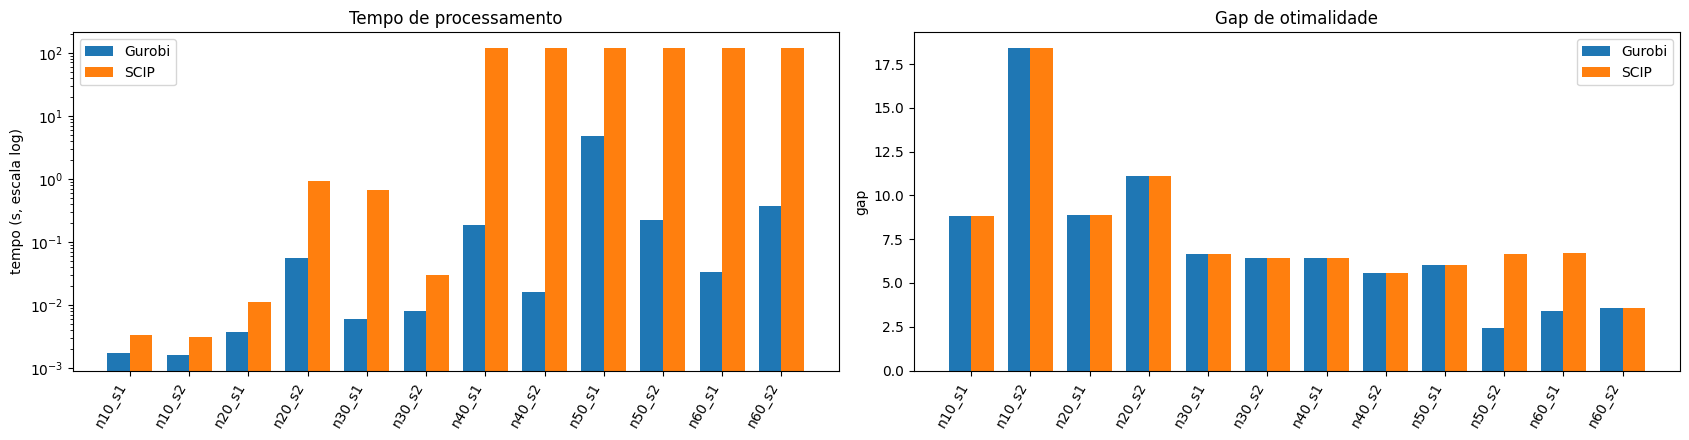

In [ ]:
piv_t = df.pivot(index="instancia", columns="solver", values="tempo")

fig, axs = plt.subplots(1, 2, figsize=(17, 4.5))
ordem = list(piv_t.index)
x = range(len(ordem))
larg = 0.38

# Tempo (escala log)
for k, s in enumerate(piv_t.columns):
    axs[0].bar([i + (k - 0.5) * larg for i in x], piv_t.loc[ordem, s].clip(lower=1e-3), larg, label=s)
axs[0].set_yscale("log"); axs[0].set_ylabel("tempo (s, escala log)")
axs[0].set_title("Tempo de processamento")

# Gap
piv_gap = df.pivot(index="instancia", columns="solver", values="gap").loc[ordem]
for k, s in enumerate(piv_gap.columns):
    axs[1].bar([i + (k - 0.5) * larg for i in x], piv_gap[s].astype(float), larg, label=s)
axs[1].set_ylabel("gap"); axs[1].set_title("Gap de integralidade")


for a in axs:
    a.set_xticks(list(x)); a.set_xticklabels(ordem, rotation=60, ha="right"); a.legend()
plt.tight_layout(); plt.show()